In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

print("All basic libraries imported successfully!")


All basic libraries imported successfully!


In [2]:
!pip install -q kaggle

In [5]:
from getpass import getpass
import os

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")

Enter your Kaggle API token: ··········


In [6]:
!kaggle datasets download -d gti-upm/leapgestrecog

Dataset URL: https://www.kaggle.com/datasets/gti-upm/leapgestrecog
License(s): CC-BY-NC-SA-4.0
100% 2.13G/2.13G [00:19<00:00, 120MB/s]



In [8]:
import zipfile
import os

zip_path = "/content/leapgestrecog.zip"
extract_path = "/content/HandGestureDataset"

print("Extracting dataset...")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Dataset location:", extract_path)

Extracting dataset...
Dataset extracted successfully!
Dataset location: /content/HandGestureDataset


In [9]:
import os

dataset_path = "/content/HandGestureDataset"

for root, dirs, files in os.walk(dataset_path):
    print("Folder:", root)
    print("Number of subfolders:", len(dirs))
    print("Number of files:", len(files))
    print("-" * 50)
    if root.count(os.sep) >= dataset_path.count(os.sep) + 2:
        dirs[:] = []

Folder: /content/HandGestureDataset
Number of subfolders: 2
Number of files: 0
--------------------------------------------------
Folder: /content/HandGestureDataset/leapgestrecog
Number of subfolders: 1
Number of files: 0
--------------------------------------------------
Folder: /content/HandGestureDataset/leapgestrecog/leapGestRecog
Number of subfolders: 10
Number of files: 0
--------------------------------------------------
Folder: /content/HandGestureDataset/leapGestRecog
Number of subfolders: 10
Number of files: 0
--------------------------------------------------
Folder: /content/HandGestureDataset/leapGestRecog/03
Number of subfolders: 10
Number of files: 0
--------------------------------------------------
Folder: /content/HandGestureDataset/leapGestRecog/02
Number of subfolders: 10
Number of files: 0
--------------------------------------------------
Folder: /content/HandGestureDataset/leapGestRecog/05
Number of subfolders: 10
Number of files: 0
-----------------------------

In [12]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Correct dataset path
dataset_path = "/content/HandGestureDataset/leapGestRecog"

# First participant folder
participant_path = os.path.join(dataset_path, "00")

# Get gesture folders
gesture_folders = sorted(os.listdir(participant_path))

print("Number of gesture classes:", len(gesture_folders))
print("Gesture classes:", gesture_folders)

Number of gesture classes: 10
Gesture classes: ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']


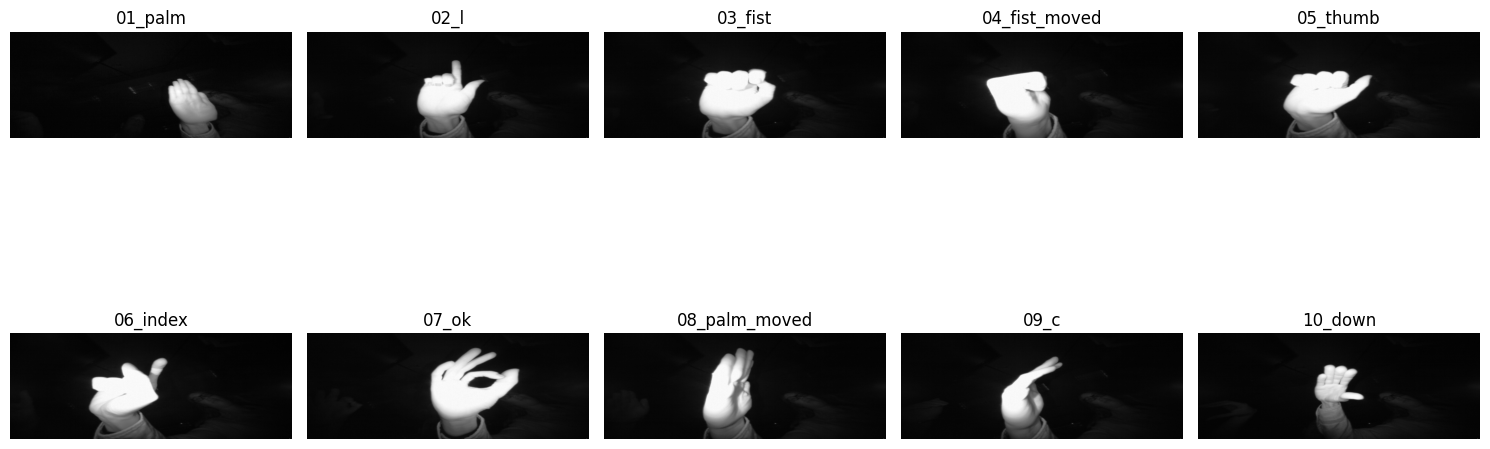

In [13]:
plt.figure(figsize=(15, 8))

for i, gesture in enumerate(gesture_folders):
    gesture_path = os.path.join(participant_path, gesture)

    images = sorted([
        f for f in os.listdir(gesture_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    if images:
        image_path = os.path.join(gesture_path, images[0])
        img = Image.open(image_path)

        plt.subplot(2, 5, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(gesture)
        plt.axis("off")

plt.tight_layout()
plt.show()

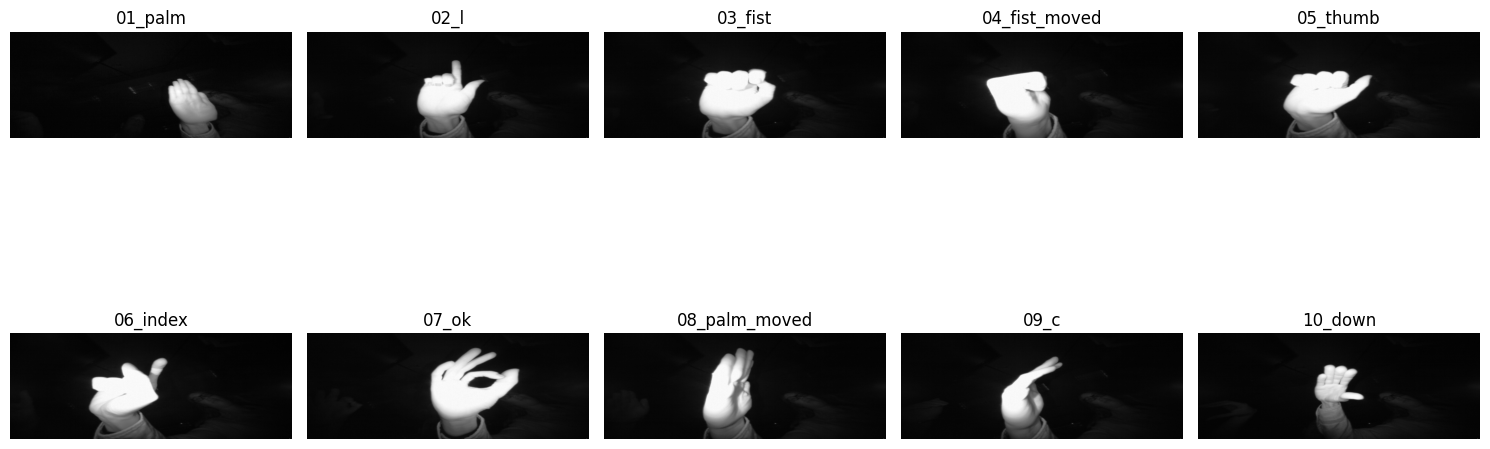

In [14]:
import os
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/HandGestureDataset/leapGestRecog"
participant_path = os.path.join(dataset_path, "00")

gesture_folders = sorted(os.listdir(participant_path))

plt.figure(figsize=(15, 8))

for i, gesture in enumerate(gesture_folders):
    gesture_path = os.path.join(participant_path, gesture)

    images = sorted([
        f for f in os.listdir(gesture_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    if images:
        image_path = os.path.join(gesture_path, images[0])
        img = Image.open(image_path)

        plt.subplot(2, 5, i + 1)
        plt.imshow(img, cmap="gray")
        plt.title(gesture)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
import os
import pandas as pd

dataset_path = "/content/HandGestureDataset/leapGestRecog"

gesture_counts = {}

for participant in sorted(os.listdir(dataset_path)):
    participant_path = os.path.join(dataset_path, participant)

    if not os.path.isdir(participant_path):
        continue

    for gesture in sorted(os.listdir(participant_path)):
        gesture_path = os.path.join(participant_path, gesture)

        if not os.path.isdir(gesture_path):
            continue

        if gesture not in gesture_counts:
            gesture_counts[gesture] = 0

        gesture_counts[gesture] += sum(
            1 for f in os.listdir(gesture_path)
            if f.lower().endswith((".png", ".jpg", ".jpeg"))
        )

df = pd.DataFrame(
    list(gesture_counts.items()),
    columns=["Gesture", "Number of Images"]
)

print(df.to_string(index=False))
print("\nTotal images:", df["Number of Images"].sum())

      Gesture  Number of Images
      01_palm              2000
         02_l              2000
      03_fist              2000
04_fist_moved              2000
     05_thumb              2000
     06_index              2000
        07_ok              2000
08_palm_moved              2000
         09_c              2000
      10_down              2000

Total images: 20000


In [16]:
import os
import numpy as np
from PIL import Image
from tqdm.notebook import tqdm

dataset_path = "/content/HandGestureDataset/leapGestRecog"

IMG_SIZE = 64

X = []
y = []

gesture_classes = sorted([
    folder for folder in os.listdir(
        os.path.join(dataset_path, "00")
    )
    if os.path.isdir(
        os.path.join(dataset_path, "00", folder)
    )
])

label_map = {
    gesture: index
    for index, gesture in enumerate(gesture_classes)
}

print("Gesture classes:", gesture_classes)
print("Number of classes:", len(gesture_classes))

Gesture classes: ['01_palm', '02_l', '03_fist', '04_fist_moved', '05_thumb', '06_index', '07_ok', '08_palm_moved', '09_c', '10_down']
Number of classes: 10


In [17]:
for participant in tqdm(sorted(os.listdir(dataset_path))):
    participant_path = os.path.join(dataset_path, participant)

    if not os.path.isdir(participant_path):
        continue

    for gesture in gesture_classes:
        gesture_path = os.path.join(participant_path, gesture)

        if not os.path.isdir(gesture_path):
            continue

        for filename in os.listdir(gesture_path):
            if filename.lower().endswith((".png", ".jpg", ".jpeg")):
                image_path = os.path.join(gesture_path, filename)

                try:
                    img = Image.open(image_path).convert("L")
                    img = img.resize((IMG_SIZE, IMG_SIZE))

                    X.append(np.array(img, dtype=np.uint8))
                    y.append(label_map[gesture])

                except Exception as e:
                    print("Could not load:", image_path, e)

X = np.array(X, dtype=np.uint8)
y = np.array(y, dtype=np.int64)

print("\nDataset loading completed!")
print("Image data shape:", X.shape)
print("Label data shape:", y.shape)
print("Total images loaded:", len(X))

  0%|          | 0/10 [00:00<?, ?it/s]


Dataset loading completed!
Image data shape: (20000, 64, 64)
Label data shape: (20000,)
Total images loaded: 20000


In [18]:
# Normalize pixel values between 0 and 1
X = X.astype("float32") / 255.0

# Check the dataset
print("Normalization completed successfully!")
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())
print("Dataset shape:", X.shape)

Normalization completed successfully!
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Dataset shape: (20000, 64, 64)


In [19]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset split completed successfully!")
print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))

Dataset split completed successfully!
Training images: 16000
Testing images: 4000
Training labels: 16000
Testing labels: 4000


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))

Training images: 16000
Testing images: 4000


In [21]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    Input
)

# Add the channel dimension to grayscale images
X_train_cnn = X_train[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

# Build the CNN model
model = Sequential([
    Input(shape=(64, 64, 1)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),

    Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,866 (6.20 MB)

 Trainable params: 1,625,866 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history = model.fit(
    X_train_cnn,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 46s 215ms/step - accuracy: 0.7749 - loss: 0.6868 - val_accuracy: 0.9931 - val_loss: 0.0340
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 83s 223ms/step - accuracy: 0.9688 - loss: 0.1003 - val_accuracy: 0.9987 - val_loss: 0.0092
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 46s 228ms/step - accuracy: 0.9809 - loss: 0.0622 - val_accuracy: 0.9994 - val_loss: 0.0055
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 46s 232ms/step - accuracy: 0.9887 - loss: 0.0374 - val_accuracy: 0.9991 - val_loss: 0.0050
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 46s 230ms/step - accuracy: 0.9915 - loss: 0.0274 - val_accuracy: 0.9984 - val_loss: 0.0047
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 43s 215ms/step - accuracy: 0.9909 - loss: 0.0288 - val_accuracy: 0.9997 - val_loss: 0.0024
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 84s 223ms/step - accuracy: 0.9924 - loss: 0.0224 - val_accuracy: 0.9997 - val_loss: 0.0026
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 47s 234ms/step - accuracy: 0.9949 - loss: 0

In [23]:
# Evaluate the model on unseen test images

test_loss, test_accuracy = model.evaluate(
    X_test_cnn,
    y_test,
    verbose=1
)

print("\n========== MODEL EVALUATION ==========")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9992 - loss: 0.0062

========== MODEL EVALUATION ==========
Test Accuracy: 99.92%
Test Loss: 0.0062


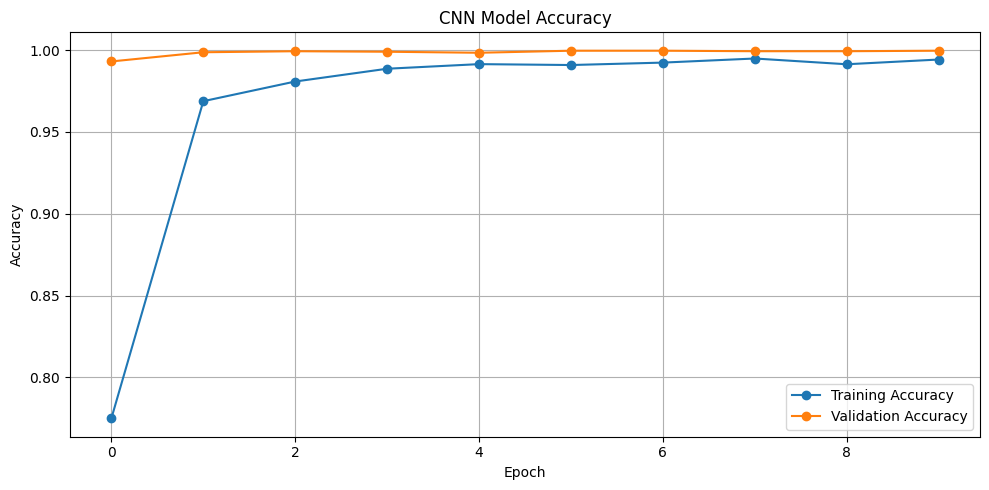

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

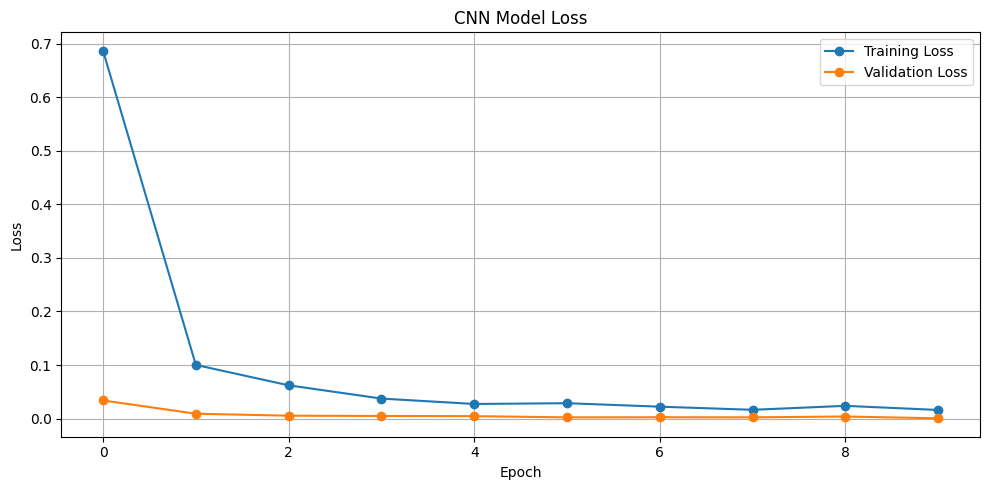

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

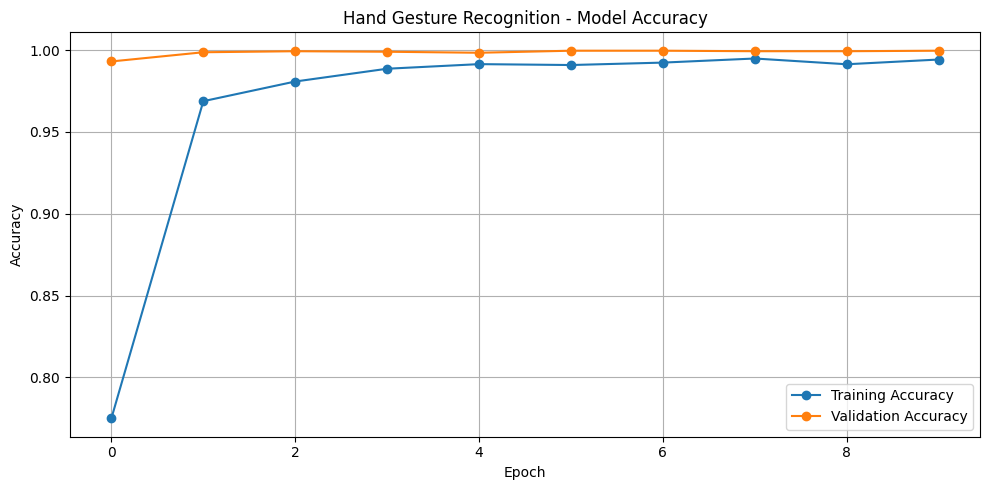

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")

plt.title("Hand Gesture Recognition - Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

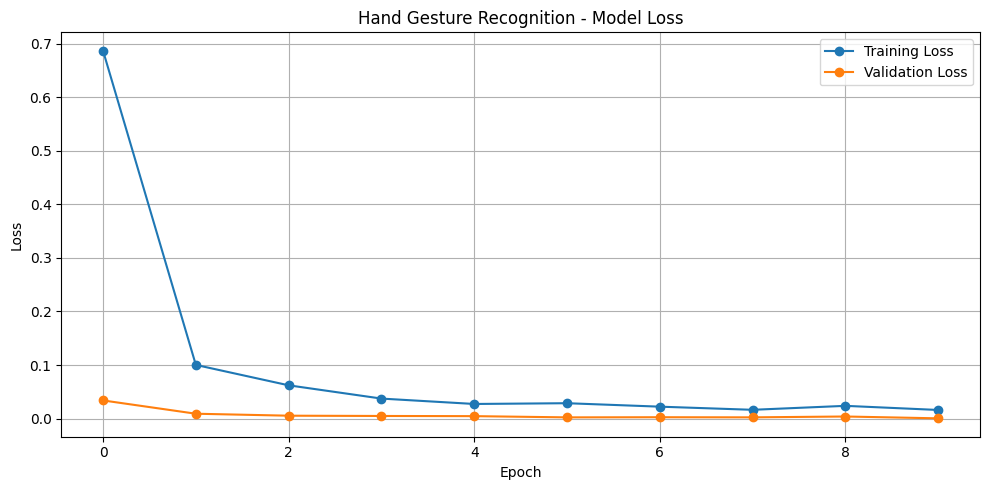

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")

plt.title("Hand Gesture Recognition - Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

125/125 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step


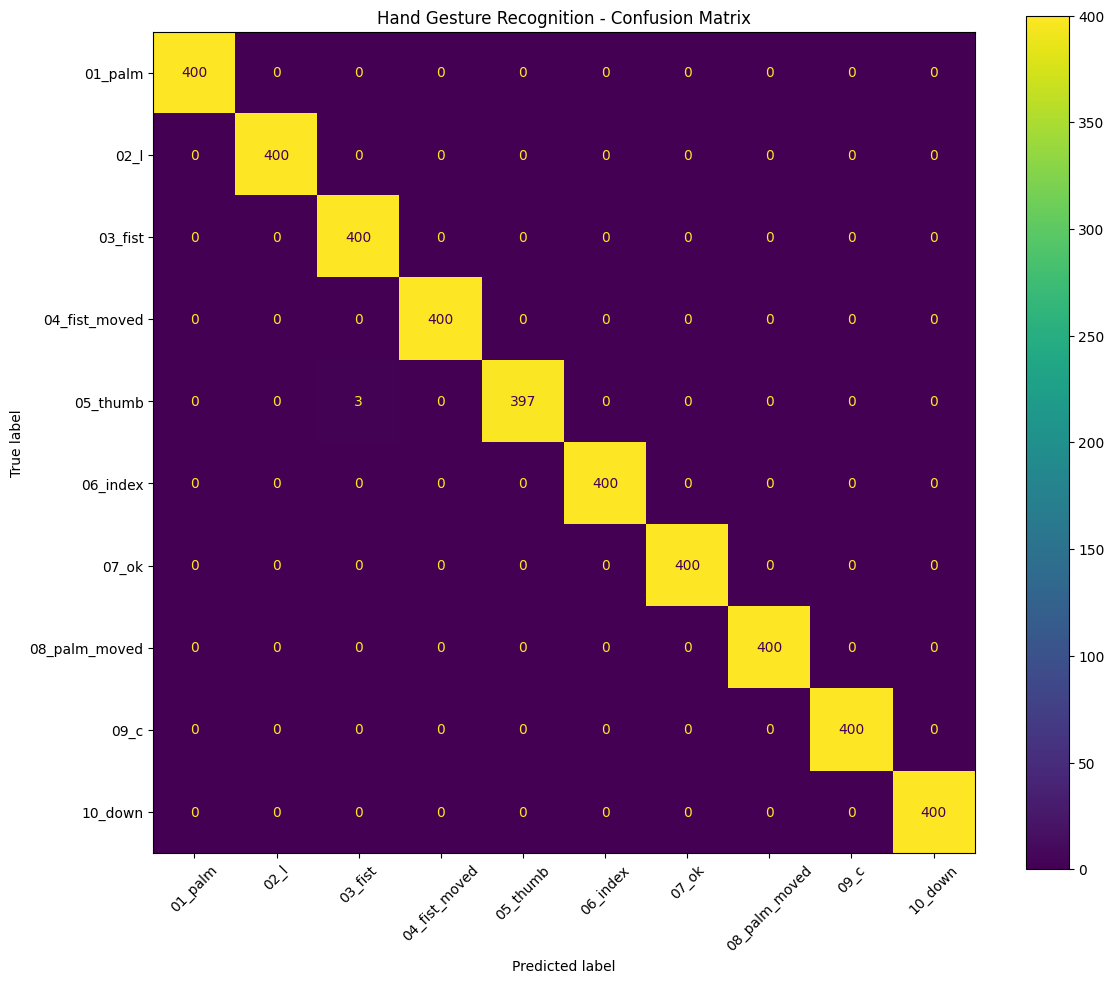

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

y_pred_prob = model.predict(X_test_cnn, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=gesture_classes
)

fig, ax = plt.subplots(figsize=(12, 10))
display.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("Hand Gesture Recognition - Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
from sklearn.metrics import classification_report

print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(gesture_classes))),
        target_names=gesture_classes,
        zero_division=0
    )
)

Classification Report:

               precision    recall  f1-score   support

      01_palm       1.00      1.00      1.00       400
         02_l       1.00      1.00      1.00       400
      03_fist       0.99      1.00      1.00       400
04_fist_moved       1.00      1.00      1.00       400
     05_thumb       1.00      0.99      1.00       400
     06_index       1.00      1.00      1.00       400
        07_ok       1.00      1.00      1.00       400
08_palm_moved       1.00      1.00      1.00       400
         09_c       1.00      1.00      1.00       400
      10_down       1.00      1.00      1.00       400

     accuracy                           1.00      4000
    macro avg       1.00      1.00      1.00      4000
 weighted avg       1.00      1.00      1.00      4000



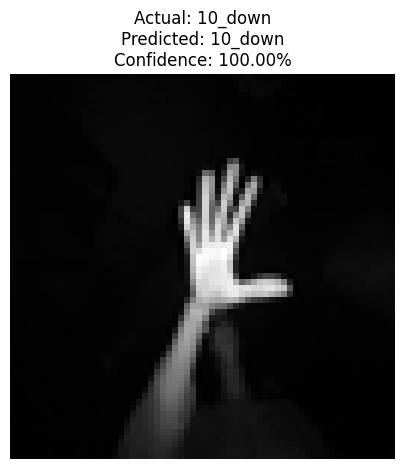

Actual gesture: 10_down
Predicted gesture: 10_down
Prediction confidence: 100.00%


In [30]:
import random
import matplotlib.pyplot as plt
import numpy as np

idx = random.randint(0, len(X_test_cnn) - 1)

image = X_test_cnn[idx]
true_label = y_test[idx]

prediction = model.predict(
    image[np.newaxis, ...],
    verbose=0
)

predicted_label = np.argmax(prediction)
confidence = np.max(prediction) * 100

plt.figure(figsize=(5, 5))
plt.imshow(image.squeeze(), cmap="gray")
plt.title(
    f"Actual: {gesture_classes[true_label]}\n"
    f"Predicted: {gesture_classes[predicted_label]}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

print("Actual gesture:", gesture_classes[true_label])
print("Predicted gesture:", gesture_classes[predicted_label])
print(f"Prediction confidence: {confidence:.2f}%")

In [31]:
# Save the trained CNN model

model.save("/content/hand_gesture_recognition_model.keras")

print("Model saved successfully!")
print("Filename: hand_gesture_recognition_model.keras")

Model saved successfully!
Filename: hand_gesture_recognition_model.keras


In [32]:
from google.colab import files

files.download("/content/hand_gesture_recognition_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>